In [114]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [115]:
df = pd.read_csv('Exam_Score_Prediction.csv')

In [116]:
df.head()

,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,1,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,2,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,3,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,4,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,5,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7


In [117]:
df.shape

(20000, 13)

In [118]:
df.columns

Index(['student_id', 'age', 'gender', 'course', 'study_hours',
       'class_attendance', 'internet_access', 'sleep_hours', 'sleep_quality',
       'study_method', 'facility_rating', 'exam_difficulty', 'exam_score'],
      dtype='str')

In [119]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        20000 non-null  int64  
 1   age               20000 non-null  int64  
 2   gender            20000 non-null  str    
 3   course            20000 non-null  str    
 4   study_hours       20000 non-null  float64
 5   class_attendance  20000 non-null  float64
 6   internet_access   20000 non-null  str    
 7   sleep_hours       20000 non-null  float64
 8   sleep_quality     20000 non-null  str    
 9   study_method      20000 non-null  str    
 10  facility_rating   20000 non-null  str    
 11  exam_difficulty   20000 non-null  str    
 12  exam_score        20000 non-null  float64
dtypes: float64(4), int64(2), str(7)
memory usage: 2.7 MB


In [120]:
df.describe()

,student_id,age,study_hours,class_attendance,sleep_hours,exam_score
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000
mean,10000.504600,20.473300,4.007604,70.017365,7.00856,62.513225
std,5773.654959,2.284458,2.308313,17.282262,1.73209,18.908491
min,1.000000,17.000000,0.080000,40.600000,4.10000,19.599000
25%,5000.750000,18.000000,2.000000,55.100000,5.50000,48.800000
50%,10000.500000,20.000000,4.040000,69.900000,7.00000,62.600000
75%,15000.250000,22.000000,6.000000,85.000000,8.50000,76.300000
max,20001.000000,24.000000,7.910000,99.400000,9.90000,100.000000


In [121]:
df.drop(columns='student_id',inplace=True)

In [122]:
df

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7
...,...,...,...,...,...,...,...,...,...,...,...,...
19995,18,other,bba,6.50,71.3,yes,5.0,good,self-study,low,easy,86.5
19996,18,male,b.com,3.71,41.6,no,5.9,average,coaching,medium,moderate,60.9
19997,19,other,diploma,7.88,68.2,yes,4.6,poor,group study,low,easy,64.5
19998,19,male,bba,4.60,76.3,no,6.1,good,self-study,medium,moderate,79.0


In [123]:
df.isna().sum()

age                 0
gender              0
course              0
study_hours         0
class_attendance    0
internet_access     0
sleep_hours         0
sleep_quality       0
study_method        0
facility_rating     0
exam_difficulty     0
exam_score          0
dtype: int64

In [124]:
df.duplicated().sum()

np.int64(0)

In [125]:
df.head()

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7


In [126]:
numerical_columns = ['age','study_hours','class_attendance','sleep_hours','exam_score']

In [127]:
df['age'].value_counts()

age
21    2555
18    2542
19    2528
17    2514
22    2497
20    2488
24    2443
23    2433
Name: count, dtype: int64

In [128]:
df['course'].value_counts()

course
bca        2902
ba         2896
b.sc       2878
b.com      2864
bba        2836
diploma    2826
b.tech     2798
Name: count, dtype: int64

In [129]:
df['study_hours'].value_counts()

study_hours
7.91    225
0.08    210
5.61     42
0.90     41
2.81     41
       ... 
1.93     14
1.14     13
0.37     13
1.84     12
5.16     11
Name: count, Length: 784, dtype: int64

In [130]:
df['internet_access'].value_counts()

internet_access
yes    16988
no      3012
Name: count, dtype: int64

In [131]:
df['sleep_quality'].value_counts()

sleep_quality
average    6694
poor       6687
good       6619
Name: count, dtype: int64

In [132]:
df['study_method'].value_counts()

study_method
self-study       4079
online videos    4069
coaching         4036
group study      3922
mixed            3894
Name: count, dtype: int64

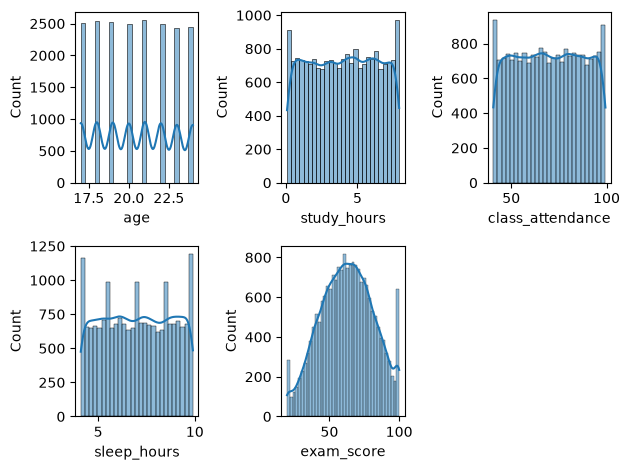

In [133]:
def plottingHisto(val,num):
    plt.subplot(2,3,num)
    sns.histplot(df[val],kde=True)
    plt.tight_layout()

plottingHisto('age',1)
plottingHisto('study_hours',2)
plottingHisto('class_attendance',3)
plottingHisto('sleep_hours',4)
plottingHisto('exam_score',5)

In [134]:
numerical_columns

['age', 'study_hours', 'class_attendance', 'sleep_hours', 'exam_score']

In [135]:
df.head()

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7


In [136]:
cat_columns = ['gender','course','internet_access','sleep_quality','study_method','facility_rating','exam_diffiuclty']

<Axes: xlabel='gender', ylabel='count'>

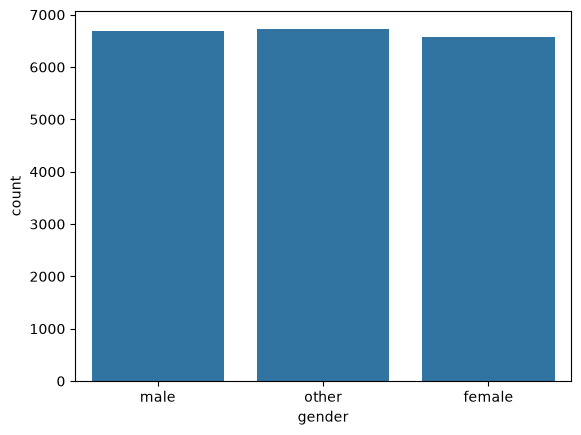

In [137]:
sns.countplot(x=df['gender'])

<Axes: xlabel='course', ylabel='count'>

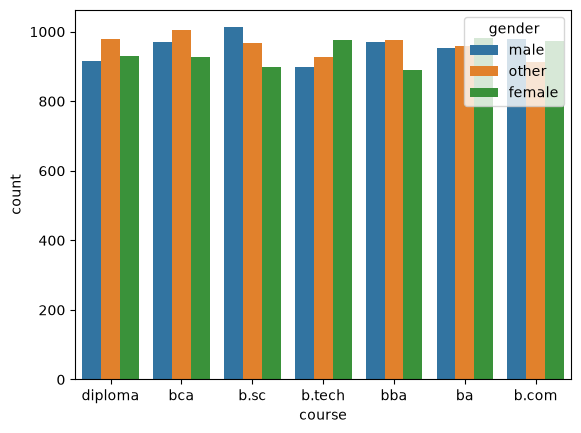

In [138]:
sns.countplot(x = df['course'],hue=df['gender'])

<Axes: xlabel='exam_difficulty', ylabel='count'>

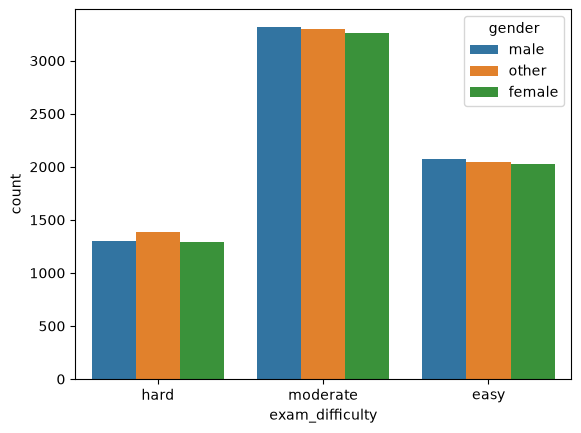

In [139]:
sns.countplot(x = df['exam_difficulty'], hue=df['gender'])

<Axes: xlabel='gender', ylabel='age'>

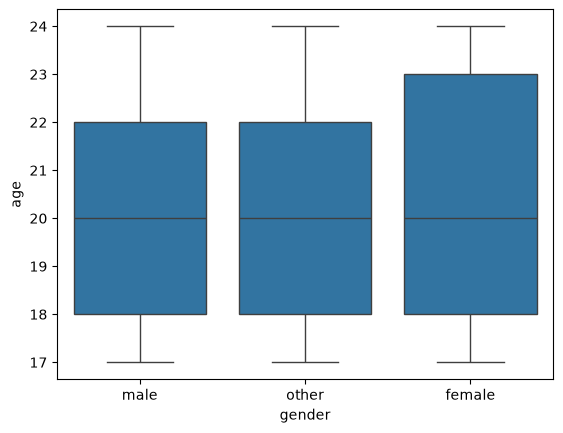

In [140]:
sns.boxplot(data=df, x='gender',y='age')

<Axes: xlabel='gender', ylabel='sleep_quality'>

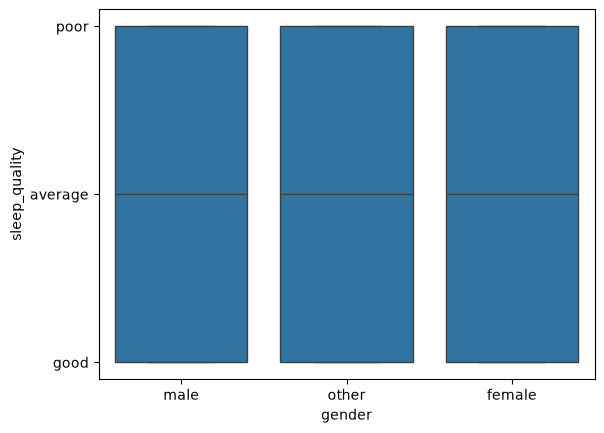

In [141]:
sns.boxplot(data=df, x='gender',y='sleep_quality')

<Axes: xlabel='sleep_quality', ylabel='count'>

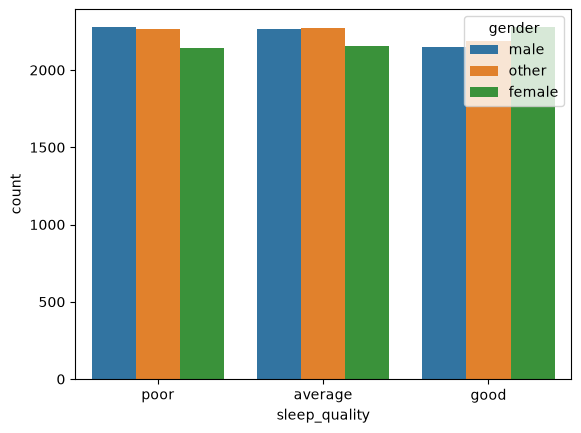

In [142]:
sns.countplot(x = df['sleep_quality'], hue=df['gender'])

<Axes: >

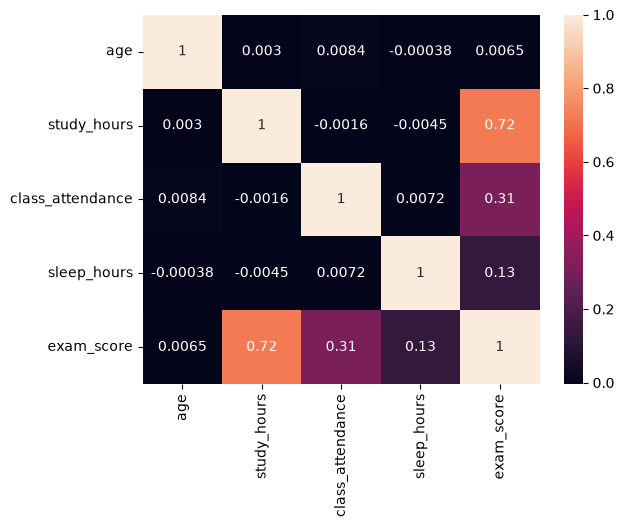

In [143]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [147]:
df_cleaned = df.copy()
df_cleaned.head()

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7


In [148]:
encode_df = pd.get_dummies(df,drop_first=True,dtype=int)

In [149]:
encode_df.head()

,age,study_hours,class_attendance,sleep_hours,exam_score,gender_male,gender_other,course_b.sc,course_b.tech,course_ba,course_bba,course_bca,course_diploma,internet_access_yes,sleep_quality_good,sleep_quality_poor,study_method_group study,study_method_mixed,study_method_online videos,study_method_self-study,facility_rating_low,facility_rating_medium,exam_difficulty_hard,exam_difficulty_moderate
0,17,2.78,92.9,7.4,58.9,1,0,0,0,0,0,0,1,1,0,1,0,0,0,0,1,0,1,0
1,23,3.37,64.8,4.6,54.8,0,1,0,0,0,0,1,0,1,0,0,0,0,1,0,0,1,0,1
2,22,7.88,76.8,8.5,90.3,1,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1
3,20,0.67,48.4,5.8,29.7,0,1,0,0,0,0,0,1,1,0,0,0,0,1,0,1,0,0,1
4,20,0.89,71.6,9.8,43.7,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,1,0,0,1


In [150]:
numerical_columns_encode = ['age','study_hours','class_attendance','sleep_hours'] 
numerical_columns_encode

['age', 'study_hours', 'class_attendance', 'sleep_hours']

In [151]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [152]:
encode_df[numerical_columns_encode] = scaler.fit_transform(encode_df[numerical_columns_encode])

In [153]:
encode_df

,age,study_hours,class_attendance,sleep_hours,exam_score,gender_male,gender_other,course_b.sc,course_b.tech,course_ba,course_bba,course_bca,course_diploma,internet_access_yes,sleep_quality_good,sleep_quality_poor,study_method_group study,study_method_mixed,study_method_online videos,study_method_self-study,facility_rating_low,facility_rating_medium,exam_difficulty_hard,exam_difficulty_moderate
0,-1.520442,-0.531832,1.324086,0.225999,58.9,1,0,0,0,0,0,0,1,1,0,1,0,0,0,0,1,0,1,0
1,1.106067,-0.276227,-0.301899,-1.390586,54.8,0,1,0,0,0,0,1,0,1,0,0,0,0,1,0,0,1,0,1
2,0.668315,1.677629,0.392472,0.861085,90.3,1,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1
3,-0.207188,-1.445942,-1.250872,-0.697764,29.7,0,1,0,0,0,0,0,1,1,0,0,0,0,1,0,1,0,0,1
4,-0.207188,-1.350632,0.091578,1.611643,43.7,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,-1.082691,1.079775,0.074219,-1.159646,86.5,0,1,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,0
19996,-1.082691,-0.128930,-1.644349,-0.640029,60.9,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1
19997,-0.644939,1.677629,-0.105160,-1.390586,64.5,0,1,0,0,0,0,0,1,1,0,1,1,0,0,0,1,0,0,0
19998,-0.644939,0.256643,0.363540,-0.524559,79.0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,1,0,1


In [40]:
selected_columns = encode_df.columns
selected_columns = selected_columns.drop('exam_score')
selected_columns

Index(['age', 'study_hours', 'class_attendance', 'sleep_hours', 'gender_male',
       'gender_other', 'course_b.sc', 'course_b.tech', 'course_ba',
       'course_bba', 'course_bca', 'course_diploma', 'internet_access_yes',
       'sleep_quality_good', 'sleep_quality_poor', 'study_method_group study',
       'study_method_mixed', 'study_method_online videos',
       'study_method_self-study', 'facility_rating_low',
       'facility_rating_medium', 'exam_difficulty_hard',
       'exam_difficulty_moderate'],
      dtype='str')

In [41]:
from scipy.stats import pearsonr
correlations = {
    feature:pearsonr(encode_df[feature],encode_df['exam_score'])[0]
    for feature in selected_columns
}

correlations_df = pd.DataFrame(list(correlations.items()), columns = ['Feature','Pearson Correlations'])

correlations_df.sort_values(by='Pearson Correlations', ascending=False)

,Feature,Pearson Correlations
1,study_hours,0.711655
2,class_attendance,0.309038
13,sleep_quality_good,0.172086
3,sleep_hours,0.130699
16,study_method_mixed,0.044999
20,facility_rating_medium,0.010549
9,course_bba,0.008863
0,age,0.006643
6,course_b.sc,0.004460
21,exam_difficulty_hard,0.003107


In [42]:
encode_df.columns

Index(['age', 'study_hours', 'class_attendance', 'sleep_hours', 'exam_score',
       'gender_male', 'gender_other', 'course_b.sc', 'course_b.tech',
       'course_ba', 'course_bba', 'course_bca', 'course_diploma',
       'internet_access_yes', 'sleep_quality_good', 'sleep_quality_poor',
       'study_method_group study', 'study_method_mixed',
       'study_method_online videos', 'study_method_self-study',
       'facility_rating_low', 'facility_rating_medium', 'exam_difficulty_hard',
       'exam_difficulty_moderate'],
      dtype='str')

In [43]:
cat_columns_encode = ['gender_male', 'gender_other', 'course_b.sc', 'course_b.tech',
       'course_ba', 'course_bba', 'course_bca', 'course_diploma',
       'internet_access_yes', 'sleep_quality_good', 'sleep_quality_poor',
       'study_method_group study', 'study_method_mixed',
       'study_method_online videos', 'study_method_self-study',
       'facility_rating_low', 'facility_rating_medium', 'exam_difficulty_hard',
       'exam_difficulty_moderate']

In [44]:
from scipy.stats import chi2_contingency
alpha = 0.05
chi2_results = {}

for col in cat_columns_encode:
    contingency = pd.crosstab(encode_df[col],encode_df['exam_score'])
    chi2_stats,p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val<alpha else 'Accept Null (Reject Feature)'
    chi2_results[col] = {
        "chi2_stats":chi2_stats,
        'p_val':p_val,
        'decision':decision
    }

chi2_df = pd.DataFrame(chi2_results).T
chi2_df =chi2_df.sort_values(by='p_val')


In [45]:
chi2_df

,chi2_stats,p_val,decision
sleep_quality_poor,698.422361,0.0,Reject Null (Keep Feature)
sleep_quality_good,695.288052,0.0,Reject Null (Keep Feature)
facility_rating_low,553.995645,0.0,Reject Null (Keep Feature)
study_method_self-study,288.590398,0.0,Reject Null (Keep Feature)
study_method_online videos,172.117227,0.0,Reject Null (Keep Feature)
study_method_mixed,114.358654,0.008669,Reject Null (Keep Feature)
study_method_group study,109.731134,0.018493,Reject Null (Keep Feature)
course_bba,97.171367,0.106339,Accept Null (Reject Feature)
course_b.tech,90.507364,0.220202,Accept Null (Reject Feature)
course_ba,89.192218,0.249799,Accept Null (Reject Feature)


In [46]:
df_final = encode_df[['sleep_quality_poor','sleep_quality_good','facility_rating_low','study_method_self-study','study_method_online videos','exam_score']]

In [47]:
df_final

,sleep_quality_poor,sleep_quality_good,facility_rating_low,study_method_self-study,study_method_online videos,exam_score
0,1,0,1,0,0,58
1,0,0,0,0,1,54
2,1,0,0,0,0,90
3,0,0,1,0,1,29
4,1,0,1,0,0,43
...,...,...,...,...,...,...
19995,0,1,1,1,0,86
19996,0,0,0,0,0,60
19997,1,0,1,0,0,64
19998,0,1,0,1,0,79


In [58]:
from sklearn.model_selection import train_test_split

In [59]:
X = df_final.drop('exam_score',axis=1)
y = df_final['exam_score']

In [69]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [70]:
X_train

,sleep_quality_poor,sleep_quality_good,facility_rating_low,study_method_self-study,study_method_online videos
7070,0,0,0,0,1
13010,0,1,0,0,0
6688,0,1,0,0,1
9976,1,0,0,0,0
5175,0,0,0,0,1
...,...,...,...,...,...
11284,1,0,0,0,0
11964,1,0,0,1,0
5390,0,1,0,0,0
860,0,1,0,0,1


In [71]:
from sklearn.linear_model import LinearRegression

In [72]:
linear_model = LinearRegression()

In [73]:
linear_model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-4.43, 4.58,-5.87,-5.9 ,-4.22]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['sleep_quality_poor','sleep_quality_good','facility_rating_low', 'study_method_self-study','study_method_online videos']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,66.14
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [74]:
y_pred = linear_model.predict(X_test)

In [75]:
from sklearn.metrics import r2_score

In [81]:
r2_acc = r2_score(y_test, y_pred)

In [82]:
r2_acc

0.07983695100301369

In [78]:
n = X_test.shape[0]
p = X_test.shape[1]

In [83]:
adjusted_r2 = 1 - ((1-r2_acc)*(n-1) / (n-p-1))

In [84]:
adjusted_r2

0.07913922348633418